<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


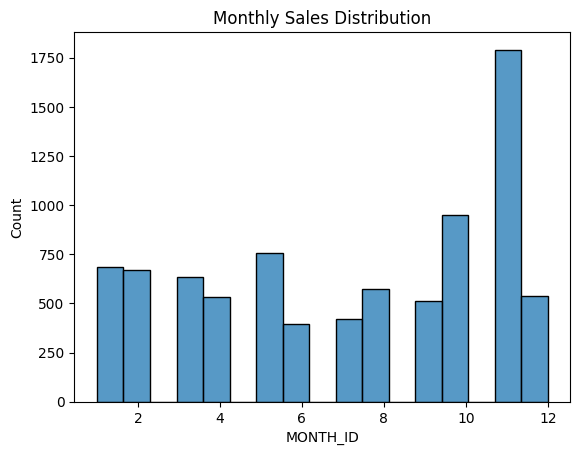

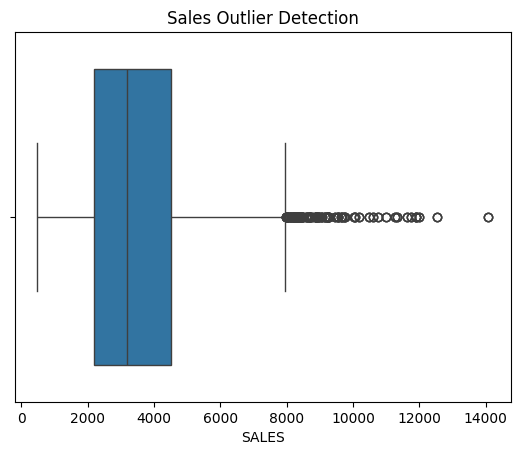

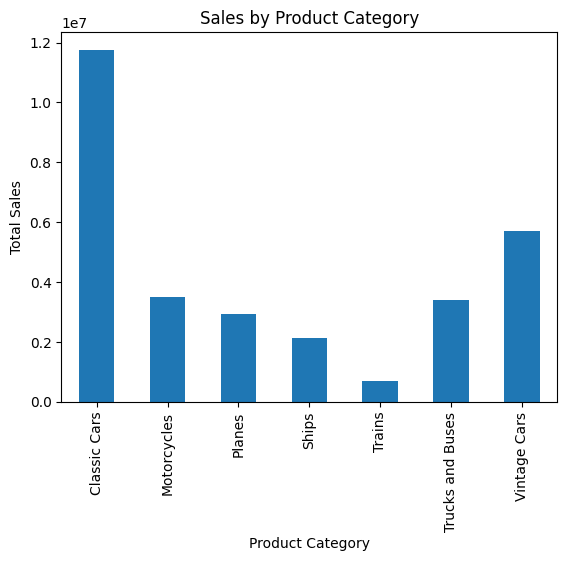

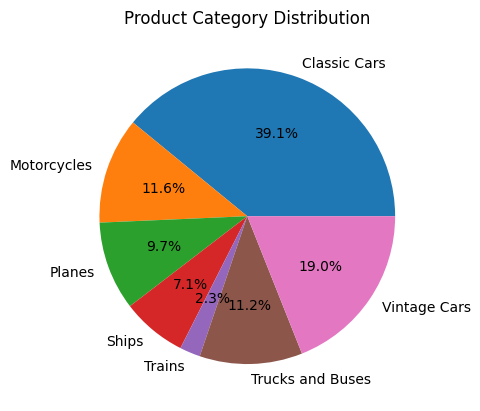

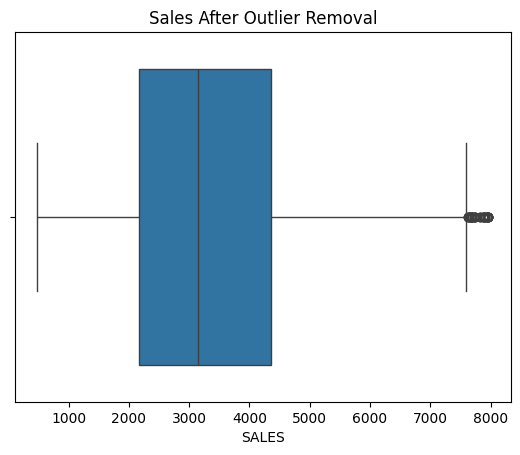

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_csv('sales_data_sample - sales_data_sample.csv', encoding='ISO-8859-1')
df2 = pd.read_json('csvjson.json')
df3 = pd.read_excel('sales_data_sample.xlsx')

df1.head()
df2.head()
df3.head()

df1.shape
df2.shape
df3.shape

df1.info()
df2.info()
df3.info()

df1.isna().sum()
df2.isna().sum()
df3.isna().sum()

df1.describe()
df2.describe()
df3.describe()

df1 = df1.drop(['ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'TERRITORY'], axis=1)
df2 = df2.drop(['ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'TERRITORY'], axis=1)
df3 = df3.drop(['ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'TERRITORY'], axis=1)

df1['POSTALCODE'] = df1['POSTALCODE'].fillna(df1['POSTALCODE'].mode()[0])

df1 = df1.drop_duplicates()
df2 = df2.drop_duplicates()
df3 = df3.drop_duplicates()

df1.isna().sum()
df2.isna().sum()
df3.isna().sum()

df = pd.concat([df1, df2, df3], ignore_index=True)

df.head()
df.shape

df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])

df['YEAR'] = df['ORDERDATE'].dt.year
df['MONTH'] = df['ORDERDATE'].dt.month

df.head()

df['SALES'].sum()

df['SALES'].mean()

average_order_value = df.groupby('ORDERNUMBER')['SALES'].sum().mean()
average_order_value

category_sales = df.groupby('PRODUCTLINE')['SALES'].sum()
category_sales

data1 = df1[df1['STATUS'] == 'Shipped']
data2 = df2[df2['STATUS'] == 'Shipped']
data3 = df3[df3['STATUS'] == 'Shipped']

data1.shape
data2.shape
data3.shape

sns.histplot(x='MONTH_ID', data=df)
plt.title('Monthly Sales Distribution')
plt.show()

sns.boxplot(x='SALES', data=df)
plt.title('Sales Outlier Detection')
plt.show()

category_sales.plot(kind='bar')
plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.show()

category_sales.plot(kind='pie', autopct='%1.1f%%')
plt.title('Product Category Distribution')
plt.ylabel('')
plt.show()

Q1 = np.percentile(df['SALES'], 25, method='midpoint')
Q3 = np.percentile(df['SALES'], 75, method='midpoint')
IQR = Q3 - Q1

df.shape

upper = np.where(df['SALES'] >= (Q3 + 1.5 * IQR))
lower = np.where(df['SALES'] <= (Q1 - 1.5 * IQR))

df.drop(upper[0], inplace=True)
df.drop(lower[0], inplace=True)

df.shape

sns.boxplot(x='SALES', data=df)
plt.title('Sales After Outlier Removal')
plt.show()
